**Task 0: Setup and First Look**

In [1]:
import numpy as np
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv('quickbite_customers.csv')

In [4]:
df['signup_date'] = pd.to_datetime(df['signup_date'])

In [5]:
df.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0


In [6]:
df.shape

(2000, 18)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             2000 non-null   object        
 1   signup_date             2000 non-null   datetime64[ns]
 2   city                    2000 non-null   object        
 3   city_tier               2000 non-null   int64         
 4   gender                  1894 non-null   object        
 5   device_type             2000 non-null   object        
 6   acquisition_channel     2000 non-null   object        
 7   age                     1861 non-null   float64       
 8   tenure_months           2000 non-null   float64       
 9   app_sessions_per_month  2000 non-null   int64         
 10  delivery_time_min       1920 non-null   float64       
 11  avg_order_value         1892 non-null   float64       
 12  customer_rating         1742 non-null   float64 

In [8]:
df.describe()

,signup_date,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
count,2000,2000.000000,1861.000000,2000.000000,2000.00000,1920.000000,1892.000000,1742.000000,1896.000000,2000.000000,2000.00000,2000.000000
mean,2024-05-28 18:57:35.999999744,1.600500,31.926384,29.507300,13.93200,34.991198,417.577696,4.290356,22.499947,18.599500,34.89650,12995.852000
min,2023-01-01 00:00:00,1.000000,0.000000,12.000000,2.00000,15.600000,57.000000,1.000000,0.000000,0.000000,5.00000,523.000000
25%,2023-09-18 18:00:00,1.000000,27.000000,20.775000,11.00000,26.200000,215.000000,4.000000,16.200000,5.000000,17.00000,4085.750000
50%,2024-05-29 12:00:00,1.000000,32.000000,29.500000,14.00000,32.250000,315.500000,4.400000,22.400000,12.000000,24.00000,7142.000000
75%,2025-02-15 06:00:00,2.000000,37.000000,37.925000,16.00000,40.500000,458.250000,4.700000,28.500000,26.000000,32.00000,12781.250000
max,2025-11-05 00:00:00,3.000000,150.000000,46.600000,29.00000,500.000000,32000.000000,5.000000,55.900000,125.000000,400.00000,855443.000000
std,NaN,0.772138,7.619334,9.981302,3.77856,19.486015,1133.673898,0.609572,9.483931,18.983606,49.27424,30336.382856


In [9]:
df.isna()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1996,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1997,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
1998,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False


In [10]:
mv_count = df.isna().sum()
mv_count

,0
customer_id,0
signup_date,0
city,0
city_tier,0
gender,106
device_type,0
acquisition_channel,0
age,139
tenure_months,0
app_sessions_per_month,0


In [11]:
mv_pct = (mv_count / len(df)) * 100
mv_pct

,0
customer_id,0.00
signup_date,0.00
city,0.00
city_tier,0.00
gender,5.30
device_type,0.00
acquisition_channel,0.00
age,6.95
tenure_months,0.00
app_sessions_per_month,0.00


**Observation**:

Out of 2,000 rows and 18 columns, 6 columns contain missing values. customer_rating has the highest missingn value (12.90%, 258 rows), followed by age (6.95%), avg_order_value (5.40%), gender (5.30%), discount_used_pct (5.20%) and delivery_time_min (4.00%).

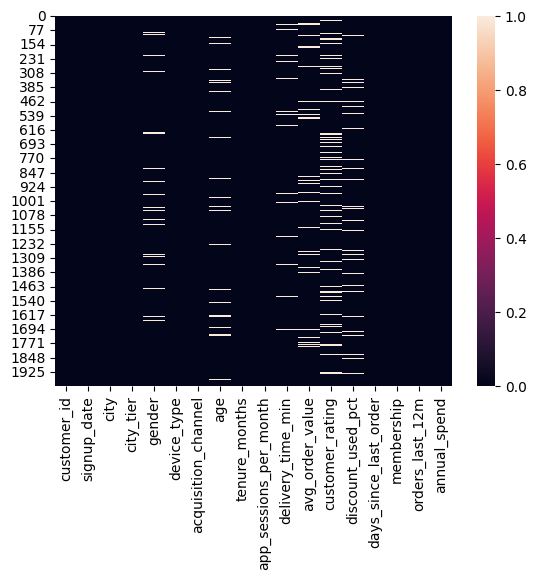

In [12]:
sns.heatmap(df.isna())
plt.show()

**Task 2: Outlier Detection and Removal**

As per the suggested Order we will handle impossible values and outliers first, then compute imputation medians(Task 1) so extreme values don't distort them.

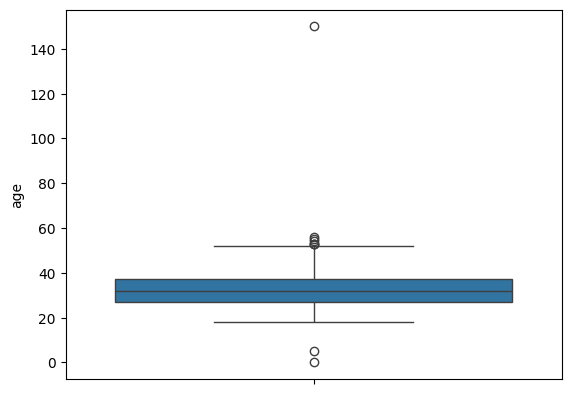

In [13]:
sns.boxplot(df['age'])
plt.show()

In [14]:
Q1_age = df['age'].quantile(0.25)
Q3_age = df['age'].quantile(0.75)
IQR_age = Q3_age - Q1_age
IQR_age

np.float64(10.0)

In [15]:
LB_age = Q1_age - 1.5 * IQR_age
UB_age = Q3_age + 1.5 * IQR_age

In [16]:
outlier_age = df[(df['age'] < LB_age) | (df['age'] > UB_age)]
outlier_age.shape

(9, 18)

In [17]:
zsc_age = (df["age"] - df['age'].mean()) / df['age'].std()
a = zsc_age[zsc_age.abs() > 3]
a.shape

(5,)

**Observation Age:**

IQR flagged 9 rows (including valid ages like 53-56), whereas Z-score flagged 5 rows (0, 5, 55, 56, 150). By comparing we can understand that ages 0, 150 and 5 are impossible ages and currently we should replace the with NaN so that we can impute it later and fix it.

In [18]:
outlier_age['age']

,age
245,5.0
257,56.0
459,55.0
572,53.0
1035,53.0
1308,53.0
1617,150.0
1792,0.0
1843,54.0


In [19]:
df.loc[a.index, 'age']

,age
245,5.0
257,56.0
459,55.0
1617,150.0
1792,0.0


In [20]:
df.loc[(df['age'] < 12) | (df['age'] > 100), 'age'] = np.nan
df.loc[a.index,'age']

,age
245,NaN
257,56.0
459,55.0
1617,NaN
1792,NaN


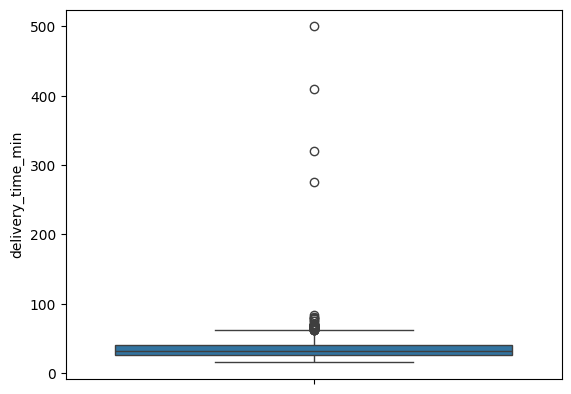

In [21]:
sns.boxplot(df['delivery_time_min'])
plt.show()

In [22]:
Q1_dtm = df['delivery_time_min'].quantile(0.25)
Q3_dtm = df['delivery_time_min'].quantile(0.75)
IQR_dtm = Q3_dtm - Q1_dtm
IQR_dtm

np.float64(14.3)

In [23]:
LB_dtm = Q1_dtm - 1.5 * IQR_dtm
UB_dtm = Q3_dtm + 1.5 * IQR_dtm

In [24]:
outlier_dtm = df[(df['delivery_time_min'] < LB_dtm) | (df['delivery_time_min'] > UB_dtm)]
outlier_dtm.shape

(46, 18)

In [25]:
zsc_dtm = (df['delivery_time_min']-df['delivery_time_min'].mean())/df['delivery_time_min'].std()
b = zsc_dtm[zsc_dtm.abs() > 3]
b.shape

(4,)

In [26]:
df.loc[b.index,['delivery_time_min','customer_rating']]

,delivery_time_min,customer_rating
1210,410.0,4.8
1223,275.0,4.5
1293,320.0,4.8
1417,500.0,5.0


**Observation Delivery Time:**

IQR flagged 46 rows due to right-skewness, whereas Z-score isolated only the 4 extreme spikes (275, 320, 410, 500 min). By comparing these extreme spikes with customer rating we found out that these extreme spikes could be some technichal glitch or the agent forgot to close the delivery as all had good customer ratings(4.5-5.0),

In [27]:
df.loc[b.index, 'delivery_time_min'] = np.nan
df.loc[b.index,['delivery_time_min','customer_rating']]

,delivery_time_min,customer_rating
1210,NaN,4.8
1223,NaN,4.5
1293,NaN,4.8
1417,NaN,5.0


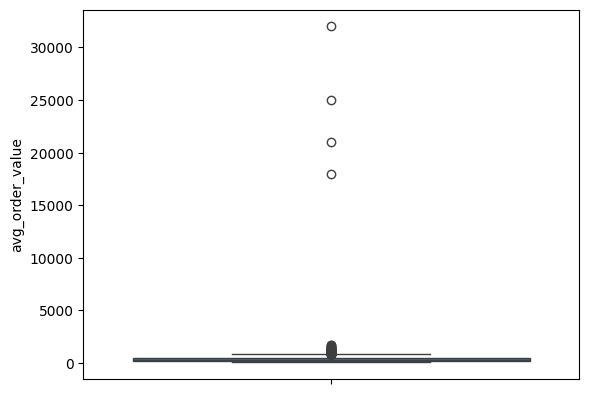

In [28]:
sns.boxplot(df['avg_order_value'])
plt.show()

In [29]:
Q1_aov = df['avg_order_value'].quantile(0.25)
Q3_aov = df['avg_order_value'].quantile(0.75)
IQR_aov = Q3_aov - Q1_aov
IQR_aov

np.float64(243.25)

In [30]:
LB_aov = Q1_aov - 1.5 * IQR_aov
UB_aov = Q3_aov + 1.5 * IQR_aov

In [31]:
outlier_aov = df[(df['avg_order_value']<LB_aov) | (df['avg_order_value']>UB_aov)]
outlier_aov.shape

(96, 18)

In [32]:
zsc_aov = (df['avg_order_value'] - df['avg_order_value'].mean())/df['avg_order_value'].std()
c = zsc_aov[zsc_aov.abs() > 3]
c.shape

(4,)

**Observation Avg Order Value:**

IQR flagged 96 rows because the basket size is naturally right-skewed, whereas Z-score isolated the 4 extreme spikes (> ₹30,000).
Takeaway: In skewed distributions, IQR flags many legitimate high-end values, whereas Z-score pinpoints extreme anomalies—though extreme values inflate the mean and std used in Z-score.


In [33]:
df.loc[c.index, 'avg_order_value'] = np.nan
df.loc[c.index, ['avg_order_value','annual_spend']]

,avg_order_value,annual_spend
156,NaN,4964.0
567,NaN,5061.0
693,NaN,7519.0
1782,NaN,826.0


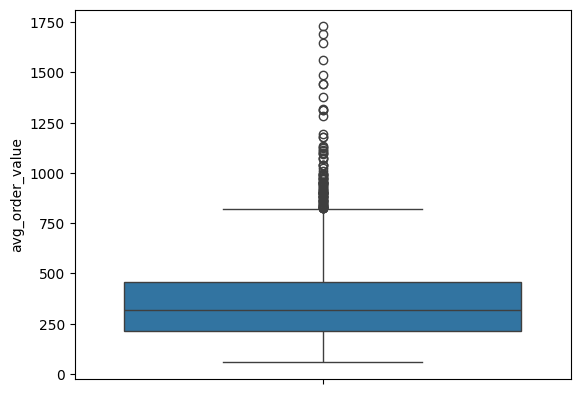

In [34]:
sns.boxplot(df['avg_order_value'])
plt.show()

In [35]:
before_df = pd.read_csv('quickbite_customers.csv')

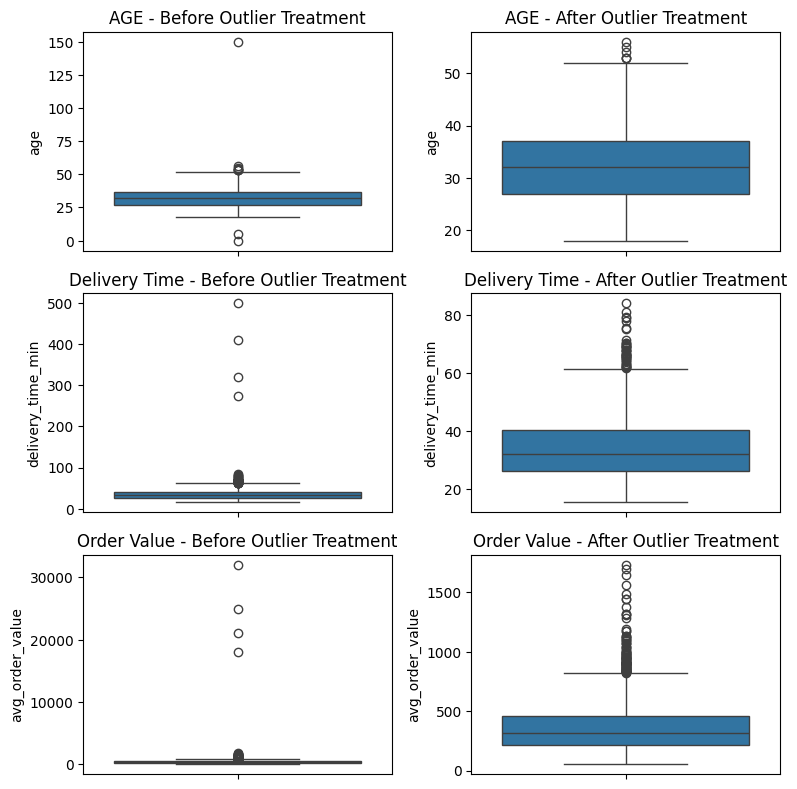

In [36]:
fig, axes = plt.subplots(3, 2, figsize=(8, 8))

sns.boxplot(y=before_df['age'],ax=axes[0,0])
axes[0,0].set_title("AGE - Before Outlier Treatment")
sns.boxplot(y=df['age'],ax=axes[0,1])
axes[0,1].set_title('AGE - After Outlier Treatment')

sns.boxplot(y=before_df['delivery_time_min'],ax=axes[1,0])
axes[1,0].set_title("Delivery Time - Before Outlier Treatment")
sns.boxplot(y=df['delivery_time_min'],ax=axes[1,1])
axes[1,1].set_title('Delivery Time - After Outlier Treatment')

sns.boxplot(y=before_df['avg_order_value'], ax=axes[2,0])
axes[2,0].set_title('Order Value - Before Outlier Treatment')
sns.boxplot(y=df['avg_order_value'], ax=axes[2,1])
axes[2,1].set_title('Order Value - After Outlier Treatment')
plt.tight_layout()
plt.show()

**Task 1: Missing Value Imputation**

In [37]:
df_before_imp = df.copy()

In [38]:
df['age'] = df['age'].fillna(df['age'].median(),inplace=False)

In [39]:
df['age'].isna().sum()

np.int64(0)

**Reflection:**

Imputing the Missing values with median instead of mean because mean is effected by extreme outliers while the median is robust against skewness and extreme outliers. Mean of age could be in decimals while in real life age is a whole number and median provides a realistic whole-number age.

In [40]:
df['delivery_time_min'] = df['delivery_time_min'].fillna(df['delivery_time_min'].median(),inplace=False)

In [41]:
df['delivery_time_min'].isna().sum()

np.int64(0)

**Reflection:**

Missing values in "delivery_time_min" were imputed using the median because, by using mean the delivery time mostly would have looked delayed as the plot is Right-Skewed and imputed values would have been drawn toward the right tail inflating the overall average delivery time and making deliveries appear more delayed.

In [42]:
df['avg_order_value'].median()

315.0

In [43]:
df.groupby('city_tier')['avg_order_value'].median()

,avg_order_value
city_tier,
1,325.0
2,309.0
3,289.5


In [44]:
df['avg_order_value'] = df['avg_order_value'].fillna(df.groupby('city_tier')['avg_order_value'].transform('median'))

In [45]:
df['avg_order_value'].isna().groupby(df['city_tier']).sum()

,avg_order_value
city_tier,
1,0
2,0
3,0


**Reflection:**

Missing values in avg_order_value were imputed using the group-wise median grouped by city_tier rather than the global median to preserve the actual distribution across the different city tier's. Using a single global median would inflate order values in lower-tier cities and underestimate values in Tier 1 cities as Tier 1 cities generally have higher taxes and order value. it would distort comparisons among all tiers. Group-wise median imputation preserves each city tier's actual and correct distribution.

In [46]:
df['customer_rating'].median()

4.4

In [47]:
df.groupby('city_tier')['customer_rating'].median()

,customer_rating
city_tier,
1,4.4
2,4.5
3,4.4


In [48]:
df.groupby(df['customer_rating'].isna())['delivery_time_min'].agg(['count', 'mean', 'median'])

,count,mean,median
customer_rating,,,
False,1742,33.145465,31.4
True,258,41.253876,39.9


In [49]:
df['customer_rating'] = df['customer_rating'].fillna(df['customer_rating'].median())

In [50]:
df['customer_rating'].isna().sum()

np.int64(0)

**Reflection:**

By comparing delivery_time_min across missing and non-missing ratings it is observed that orders with missing customer_rating had a noticeably higher average delivery time (mean- 41.25 min, median- 39.9 min) compared to orders with recorded ratings (mean- 33.15 min, median- 31.4 min).
Insight -> Customers experiencing delayed deliveries are more likely to skip leaving a rating.

following given guidlines missing values are imputed with global median(left-skewed). Comparing the global median (4.4) against group-wise medians by city_tier (Tier 1: 4.4, Tier 2: 4.5, Tier 3: 4.4) reflected that ratings are nearly identical across all city tiers, hence, global median imputation is sufficient without needing tier-level grouping.

In [51]:
df['discount_used_pct'].agg(['mean','median'])

,discount_used_pct
mean,22.499947
median,22.400000


In [52]:
df.groupby('city_tier')['discount_used_pct'].agg(['mean','median'])

,mean,median
city_tier,,
1,22.786996,22.9
2,21.821983,21.4
3,22.503235,22.9


In [53]:
df['discount_used_pct'] = df['discount_used_pct'].fillna(df['discount_used_pct'].median())

In [54]:
df['discount_used_pct'].isna().sum()

np.int64(0)

**Reflection**

Comparing the mean (22.50%) and median (22.40%) of discount_used_pct showed that both metrics are nearly identical. it shows that it is a balanced, roughly symmetric distribution with no extreme outliers. Since both measures yield virtually the same central value, missing values were imputed using the median (22.40%) to maintain consistency without distorting the distribution.

In [55]:
df['gender'].value_counts(dropna=False)

,count
gender,
Male,1023
Female,836
NaN,106
Other,35


In [56]:
df['gender'] = df['gender'].fillna('Unknown')

In [57]:
df['gender'].isna().sum()

np.int64(0)

**Reflection**

Missing values in gender and are imputed as a new "Unknown" category rather than using the mode ("Male") as "Male" (1,023) and "Female" (836) have a fairly close split and the mode doesn't have a overwhelming dominance while comparing. Creating an "Unknown" category is more honest and preserves data integrity.

In [58]:
imputed_cols = ['age', 'delivery_time_min', 'avg_order_value', 'customer_rating', 'discount_used_pct']

comparison_df = pd.DataFrame({
    'Missing_Before': df_before_imp[imputed_cols].isna().sum(),
    'Missing_After': df[imputed_cols].isna().sum(),
    'Mean_Before': df_before_imp[imputed_cols].mean().round(2),
    'Mean_After': df[imputed_cols].mean().round(2),
    'Median_Before': df_before_imp[imputed_cols].median().round(2),
    'Median_After': df[imputed_cols].median().round(2),
    'Std_Before': df_before_imp[imputed_cols].std().round(2),
    'Std_After': df[imputed_cols].std().round(2)
})

comparison_df

,Missing_Before,Missing_After,Mean_Before,Mean_After,Median_Before,Median_After,Std_Before,Std_After
age,142,0,31.89,31.90,32.0,32.0,7.05,6.79
delivery_time_min,84,0,34.28,34.19,32.2,32.2,11.01,10.78
avg_order_value,112,0,367.61,364.61,315.0,316.0,219.73,213.87
customer_rating,258,0,4.29,4.30,4.4,4.4,0.61,0.57
discount_used_pct,104,0,22.50,22.49,22.4,22.4,9.48,9.23


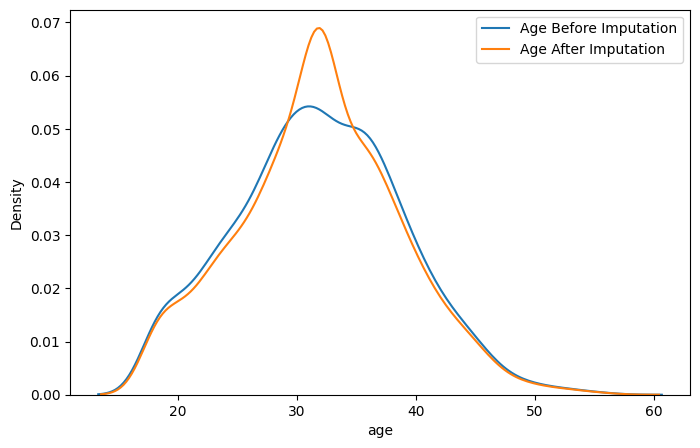

In [59]:
plt.figure(figsize=(8, 5))
sns.kdeplot(df_before_imp['age'],label='Age Before Imputation')
sns.kdeplot(df['age'],label='Age After Imputation')
plt.legend()
plt.show()


**Task 3: Distribution Shapes with KDE Plots**

In [60]:
skew_col = ['age', 'customer_rating', 'delivery_time_min', 'avg_order_value']
df[skew_col].skew()

,0
age,0.129768
customer_rating,-1.810939
delivery_time_min,1.005594
avg_order_value,1.829124


In [61]:
np.log(df['avg_order_value'].skew())

np.float64(0.6038371816596785)

**Histogram with a KDE curve for Age:**

In [62]:
mean_age = df['age'].mean()
median_age = df['age'].median()
mode_age = df['age'].mode()[0]
skew_age = df['age'].skew()

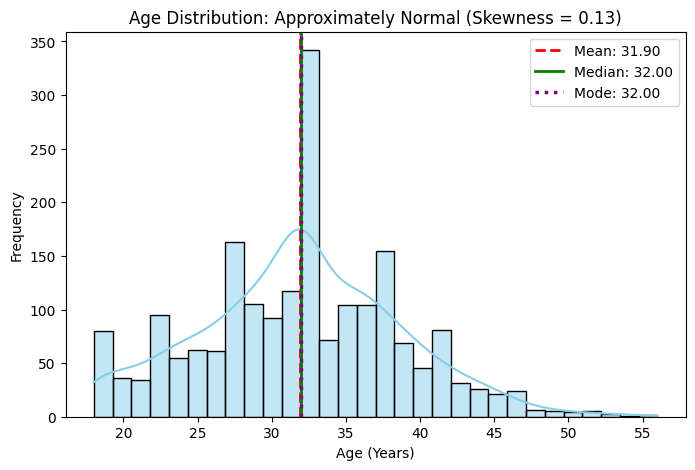

In [63]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df['age'], kde=True, color='skyblue')

plt.axvline(mean_age, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_age:.2f}')
plt.axvline(median_age, color='green', linestyle='-', linewidth=2, label=f'Median: {median_age:.2f}')
plt.axvline(mode_age, color='purple', linestyle=':', linewidth=2.5, label=f'Mode: {mode_age:.2f}')

plt.title(f'Age Distribution: Approximately Normal (Skewness = {skew_age:.2f})')
plt.xlabel('Age (Years)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

**Histogram with a KDE curve for Delivery Time:**



In [64]:
mean_dtm = df['delivery_time_min'].mean()
median_dtm = df['delivery_time_min'].median()
mode_dtm = df['delivery_time_min'].mode()[0]
skew_dtm = df['delivery_time_min'].skew()

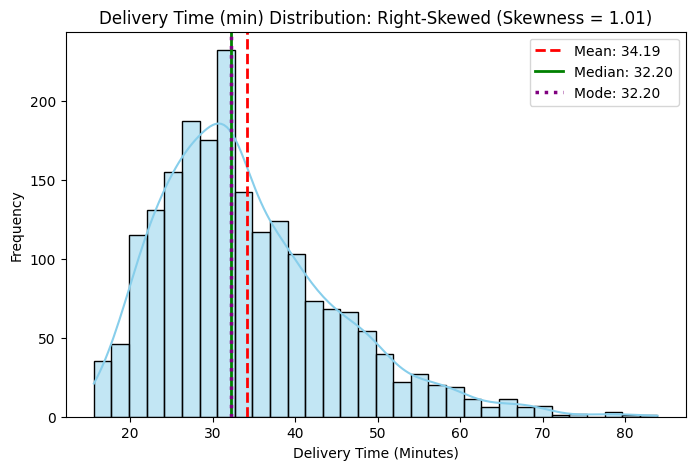

In [65]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df['delivery_time_min'], kde=True, color='skyblue')

plt.axvline(mean_dtm, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_dtm:.2f}')
plt.axvline(median_dtm, color='green', linestyle='-', linewidth=2, label=f'Median: {median_dtm:.2f}')
plt.axvline(mode_dtm, color='purple', linestyle=':', linewidth=2.5, label=f'Mode: {mode_dtm:.2f}')

plt.title(f'Delivery Time (min) Distribution: Right-Skewed (Skewness = {skew_dtm:.2f})')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

**Histogram with a KDE curve for Customer Rating:**


In [66]:
mean_cr = df['customer_rating'].mean()
median_cr = df['customer_rating'].median()
mode_cr = df['customer_rating'].mode()[0]
skew_cr = df['customer_rating'].skew()

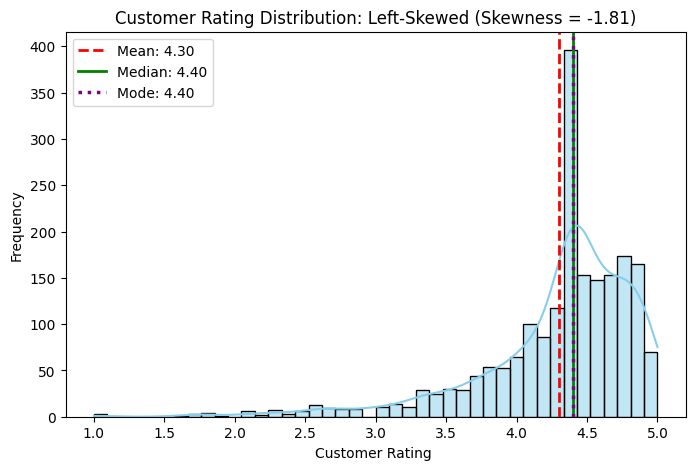

In [67]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df['customer_rating'], kde=True, color= 'skyblue')

plt.axvline(mean_cr, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_cr:.2f}')
plt.axvline(median_cr, color='green', linestyle='-', linewidth=2, label=f'Median: {median_cr:.2f}')
plt.axvline(mode_cr, color='purple', linestyle=':', linewidth=2.5, label=f'Mode: {mode_cr:.2f}')

plt.title(f'Customer Rating Distribution: Left-Skewed (Skewness = {skew_cr:.2f})')
plt.xlabel('Customer Rating ')
plt.ylabel('Frequency')
plt.legend()
plt.show()

**Histogram with a KDE curve for Avg Order Value:**


In [68]:
mean_aov = df['avg_order_value'].mean()
median_aov = df['avg_order_value'].median()
mode_aov = df['avg_order_value'].mode()[0]
skew_aov = df['avg_order_value'].skew()

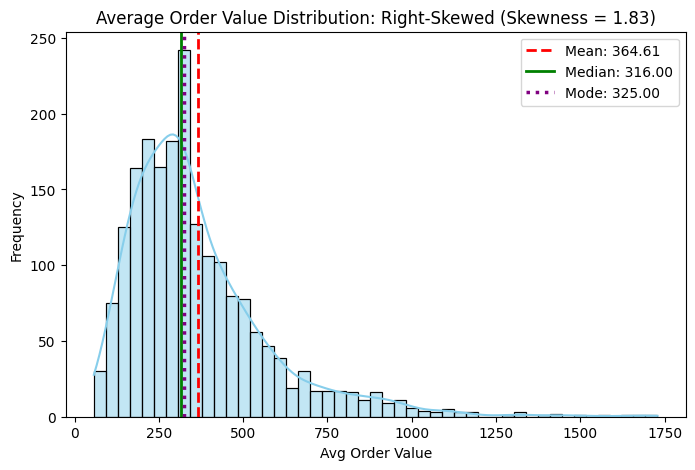

In [69]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df['avg_order_value'], kde=True, color='skyblue')

plt.axvline(mean_aov, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_aov:.2f}')
plt.axvline(median_aov, color='green', linestyle='-', linewidth=2, label=f'Median: {median_aov:.2f}')
plt.axvline(mode_aov, color='purple', linestyle=':', linewidth=2.5, label=f'Mode: {mode_aov:.2f}')

plt.title(f'Average Order Value Distribution: Right-Skewed (Skewness = {skew_aov:.2f})')
plt.xlabel('Avg Order Value')
plt.ylabel('Frequency')
plt.legend()
plt.show()

**Histogram with a KDE curve for Log(avg_order_Value):**




In [70]:
mean_naov = np.log(df['avg_order_value']).mean()
median_naov = np.log(df['avg_order_value']).median()
mode_naov = np.log(df['avg_order_value']).mode()[0]
skew_naov = np.log(df['avg_order_value']).skew()

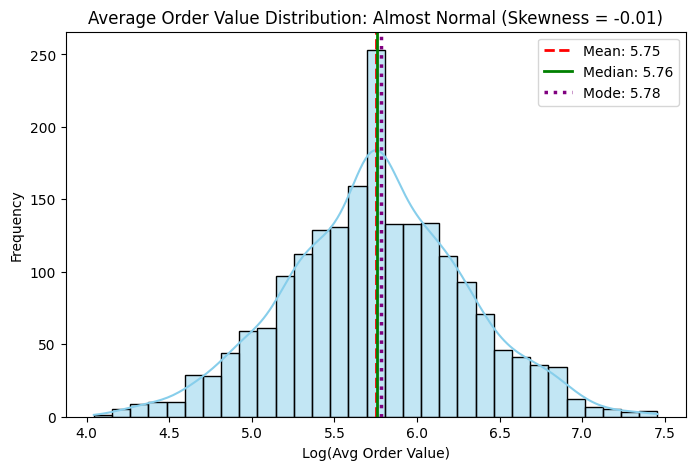

In [71]:
plt.figure(figsize=(8, 5))
sns.histplot(data=np.log(df['avg_order_value']), kde=True, color='skyblue')

plt.axvline(mean_naov, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_naov:.2f}')
plt.axvline(median_naov, color='green', linestyle='-', linewidth=2, label=f'Median: {median_naov:.2f}')
plt.axvline(mode_naov, color='purple', linestyle=':', linewidth=2.5, label=f'Mode: {mode_naov:.2f}')

plt.title(f'Average Order Value Distribution: Almost Normal (Skewness = {skew_naov:.2f})')
plt.xlabel('Log(Avg Order Value)')
plt.ylabel('Frequency')
plt.legend()
plt.show()


**REFLECTION TASK 3:**

Approximately Normal (age, log(avg_order_value)):

The Mean, Median and Mode sit very close together near the peak in the center because the data is symmetric and balanced.

Right-Skewed (delivery_time_min, avg_order_value):

Most observations cluster around the peak value(Mode), while a few large values stretch the tail to the right. Since the Mean is sensitive to extreme values, it gets pulled toward the right tail and median is between mode and mean at center as it is not much effected by the extreme values.
Mode < Median < Mean.

Left-Skewed (customer_rating): Most customers give high ratings (4-5, pushing the Mode to the right), while some number of low ratings create a long tail on the left. These low outliers pull the Mean downward toward the left tail, flipping the order to Mean < Median < Mode.

**Task 4: Relationships Between Variables**

**Covariance matrix and correlation matrix**

In [72]:
df.corr(numeric_only=True)

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
city_tier,1.000000,0.013701,0.015230,0.017946,0.213243,-0.121428,-0.004324,-0.021876,0.025767,0.024920,-0.004363
age,0.013701,1.000000,0.015538,-0.016061,0.056633,0.012217,-0.004858,-0.254862,-0.014382,0.008712,0.026315
tenure_months,0.015230,0.015538,1.000000,-0.005137,-0.006635,-0.013107,0.019056,-0.001715,-0.015789,-0.015602,-0.012000
app_sessions_per_month,0.017946,-0.016061,-0.005137,1.000000,-0.038649,0.003788,0.009966,-0.026629,0.026086,0.075177,0.084869
delivery_time_min,0.213243,0.056633,-0.006635,-0.038649,1.000000,-0.033525,-0.006600,-0.006587,-0.006395,-0.007427,-0.006611
avg_order_value,-0.121428,0.012217,-0.013107,0.003788,-0.033525,1.000000,0.007329,-0.001230,-0.035909,0.020413,0.252207
customer_rating,-0.004324,-0.004858,0.019056,0.009966,-0.006600,0.007329,1.000000,-0.002934,-0.066676,-0.006601,0.000861
discount_used_pct,-0.021876,-0.254862,-0.001715,-0.026629,-0.006587,-0.001230,-0.002934,1.000000,-0.034593,0.012921,-0.029631
days_since_last_order,0.025767,-0.014382,-0.015789,0.026086,-0.006395,-0.035909,-0.066676,-0.034593,1.000000,0.009438,-0.016463
orders_last_12m,0.024920,0.008712,-0.015602,0.075177,-0.007427,0.020413,-0.006601,0.012921,0.009438,1.000000,0.724713


In [73]:
df.cov(numeric_only=True)

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
city_tier,0.596198,0.071885,0.117375,0.052360,1.775072,-2.005203e+01,-0.001903,-0.155975,0.377689,9.481258e-01,-1.021972e+02
age,0.071885,46.170481,1.053792,-0.412370,4.148536,1.775361e+01,-0.018818,-15.990960,-1.855177,2.916815e+00,5.424296e+03
tenure_months,0.117375,1.053792,99.626390,-0.193750,-0.713935,-2.797849e+01,0.108426,-0.158046,-2.991722,-7.673531e+00,-3.633604e+03
app_sessions_per_month,0.052360,-0.412370,-0.193750,14.277515,-1.574369,3.060976e+00,0.021467,-0.929122,1.871202,1.399696e+01,9.728321e+03
delivery_time_min,1.775072,4.148536,-0.713935,-1.574369,116.222933,-7.729596e+01,-0.040562,-0.655718,-1.308779,-3.945458e+00,-2.162072e+03
avg_order_value,-20.052031,17.753608,-27.978489,3.060976,-77.295962,4.573956e+04,0.893479,-2.428539,-145.791291,2.151166e+02,1.636312e+06
customer_rating,-0.001903,-0.018818,0.108426,0.021467,-0.040562,8.934790e-01,0.324972,-0.015444,-0.721559,-1.854270e-01,1.489031e+01
discount_used_pct,-0.155975,-15.990960,-0.158046,-0.929122,-0.655718,-2.428539e+00,-0.015444,85.265970,-6.063885,5.879196e+00,-8.300506e+03
days_since_last_order,0.377689,-1.855177,-2.991722,1.871202,-1.308779,-1.457913e+02,-0.721559,-6.063885,360.377288,8.827962e+00,-9.480868e+03
orders_last_12m,0.948126,2.916815,-7.673531,13.996960,-3.945458,2.151166e+02,-0.185427,5.879196,8.827962,2.427951e+03,1.083302e+06


**OBSERVATION:**

Correlation is easier to interpret because it's value always lie between -1 to +1 removing unit/scale differences which makes it easier to compare the two different variables and understand the relationship between them while covariance is dependable on units of variables. eg - INR/$ for annual spend and Minutes for delivery time making it hard to compare both the variables or relationship between them.

**Heatmap of the correlation matrix with annotations**

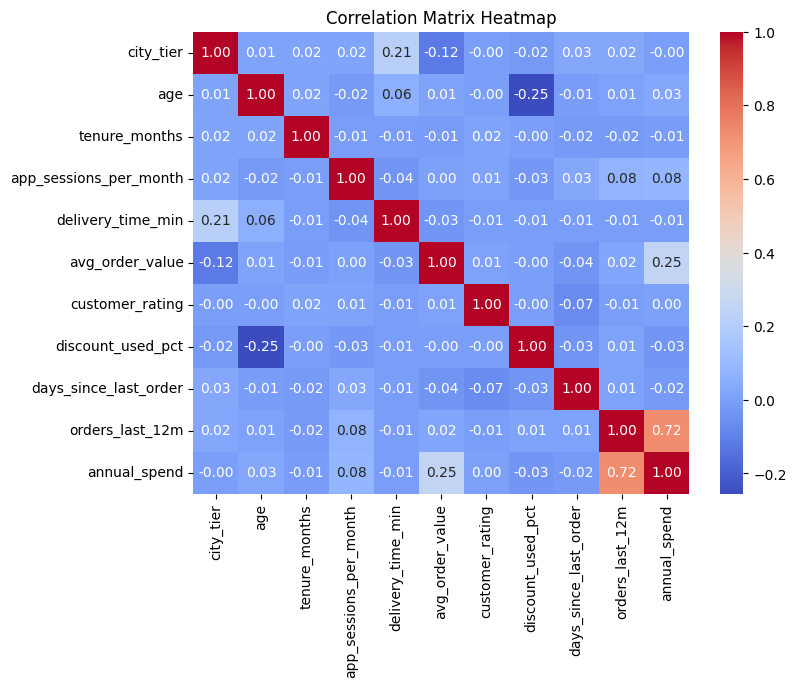

In [74]:
plt.figure(figsize=(8,6))
plt.title('Correlation Matrix Heatmap')
sns.heatmap(df.corr(numeric_only=True),annot=True,fmt='.2f',cmap='coolwarm')
plt.show()

**Obserrvation HeatMap:**

Most variables in the dataset have very weak or almost zero correlation with each other, values close to 0.00. The strongest positive relationship is between orders_last_12m and annual_spend (0.72), which shows that customers who order more frequently spend much more annually.

Also, age and discount_used_pct show a slight negative correlation (-0.25), which means younger customers use more discounts than older age people.

**Scatter plots:**

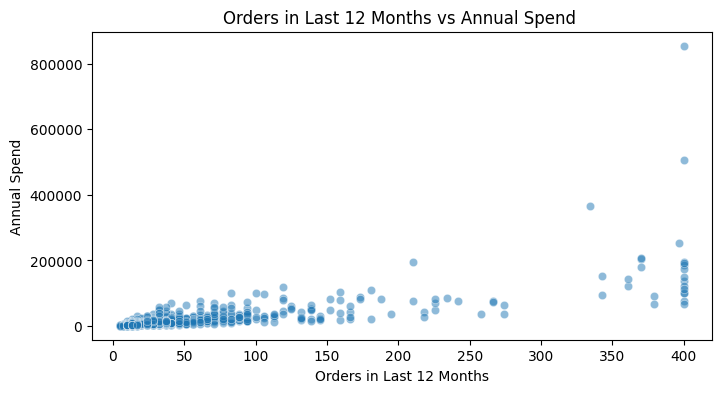

In [75]:
plt.figure(figsize=(8,4))
plt.title('Orders in Last 12 Months vs Annual Spend ')
plt.xlabel('Orders in Last 12 Months')
plt.ylabel('Annual Spend')
sns.scatterplot(data=df,x='orders_last_12m',y='annual_spend',alpha=0.5)
plt.show()

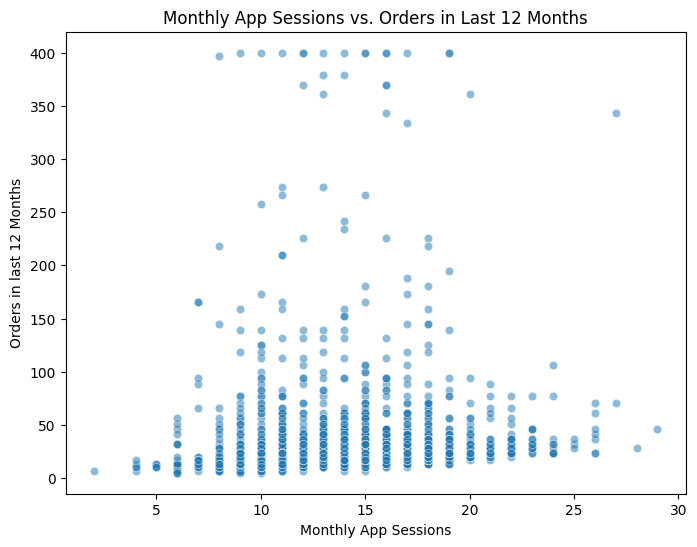

In [76]:
plt.figure(figsize=(8,6))
plt.title('Monthly App Sessions vs. Orders in Last 12 Months')
plt.xlabel('Monthly App Sessions')
plt.ylabel('Orders in last 12 Months')
sns.scatterplot(data=df,x='app_sessions_per_month',y='orders_last_12m',alpha=0.5)
plt.show()

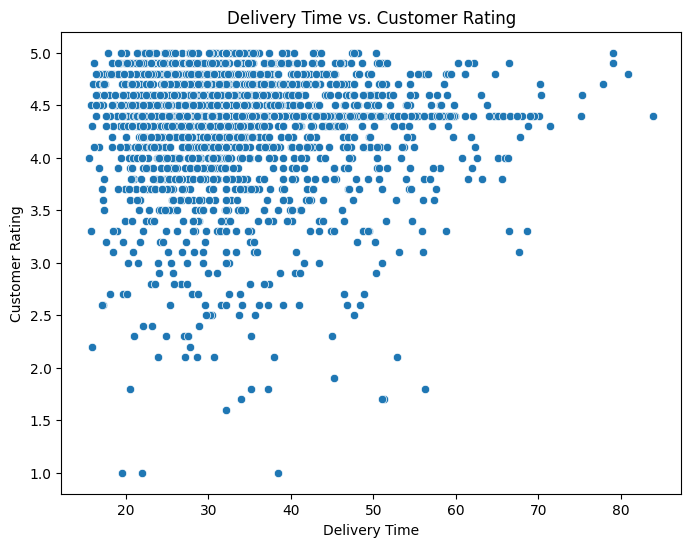

In [77]:
plt.figure(figsize=(8,6))
plt.title('Delivery Time vs. Customer Rating')
plt.xlabel('Delivery Time')
plt.ylabel('Customer Rating')
sns.scatterplot(data=df,x='delivery_time_min',y='customer_rating')
plt.show()

**Observations (Scatter Plots):**

Orders_last_12m vs annual_spend ($r = 0.72$): Shows a clear, strong positive linear trend—customers who place more orders spend significantly more annually.   app_sessions_per_month vs orders_last_12m ($r = 0.08$): Widely scattered with no clear trend, indicating that *frequent* app opens/browsing do not automatically translate into more orders.   delivery_time_min vs customer_rating ($r = -0.01$): Flat and dispersed with heavy clustering in the 4.0–5.0 rating band, showing little direct linear correlation among submitted ratings.

**LINE PLOTS:**

In [78]:
df['signup_month'] = df['signup_date'].dt.to_period('M').astype(str)

In [79]:
new_signup = df.groupby('signup_month')['customer_id'].count()
new_signup

,customer_id
signup_month,
2023-01,54
2023-02,62
2023-03,53
2023-04,65
2023-05,56
2023-06,57
2023-07,65
2023-08,54
2023-09,67


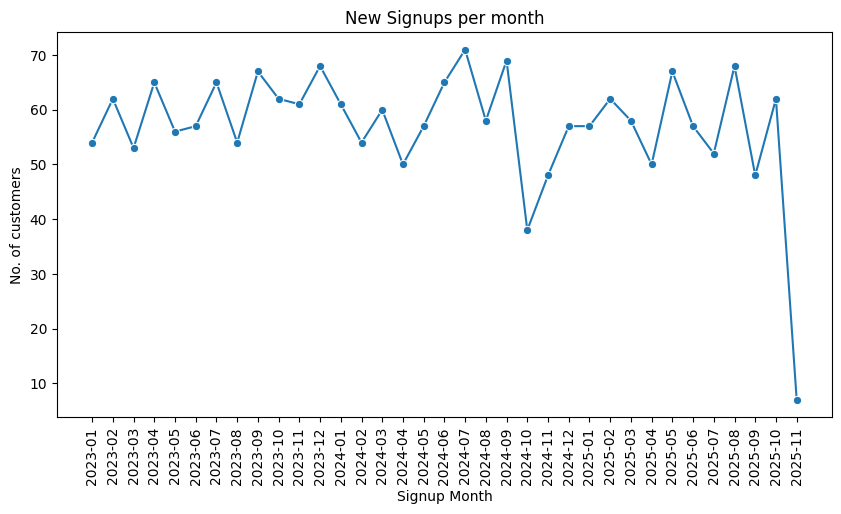

In [80]:
plt.figure(figsize=(10,5))
sns.lineplot(x=new_signup.index, y=new_signup.values, marker='o')
plt.title('New Signups per month')
plt.xlabel('Signup Month')
plt.ylabel('No. of customers')
plt.xticks(rotation=90)
plt.show()


In [81]:
monthly_avg_dtm = df.groupby('signup_month')['delivery_time_min'].mean()
monthly_avg_dtm

,delivery_time_min
signup_month,
2023-01,32.592593
2023-02,34.345161
2023-03,35.009434
2023-04,34.149231
2023-05,35.733929
2023-06,32.657895
2023-07,36.224615
2023-08,33.503704
2023-09,33.774627


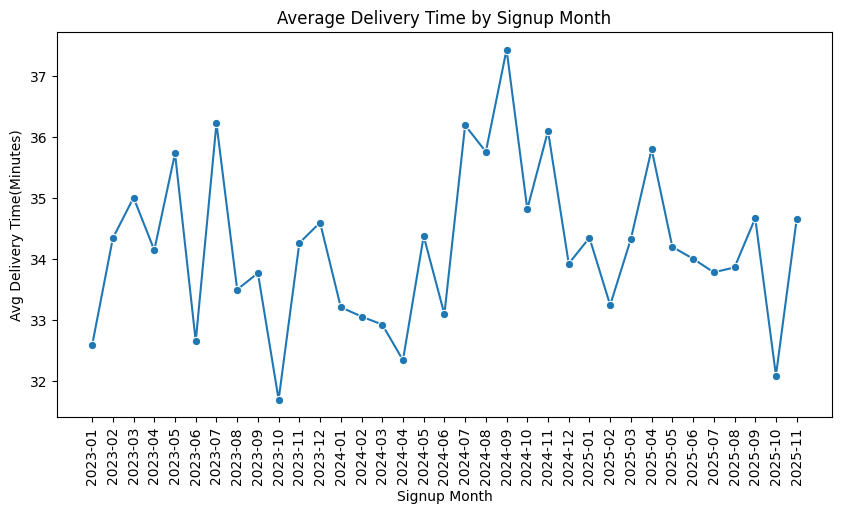

In [82]:
plt.figure(figsize=(10,5))
sns.lineplot(x=monthly_avg_dtm.index, y=monthly_avg_dtm.values, marker='o')
plt.title('Average Delivery Time by Signup Month')
plt.xlabel('Signup Month')
plt.ylabel('Avg Delivery Time(Minutes)')
plt.xticks(rotation=90)
plt.show()

**OBSERVATION LINE PLOT:**

After Comparing both the line plots, the data shows

New Signups per Month: Monthly signups remained steady between 50 and 70 customers from early 2023 through October 2025, peaking in July 2024 (71 signups). The sharp drop in November 2025 (7 signups) likely reflects an incomplete/partial month at the time the dataset was extracted rather than an actual business collapse.

Average Delivery Time by Signup Month: Monthly average delivery times stayed relatively stable within a narrow band of 32 to 37.5 minutes across all signup cohorts, showing no major upward or downward drift over time.   

**Box plots:** annual_spend by membership , delivery_time_min by
city_tier

In [83]:
df.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend,signup_month
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,4.4,21.6,4.0,Basic,17,8675.0,2023-11
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0,2025-05
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0,2023-02
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,4.4,42.9,7.0,Basic,379,90202.0,2024-04
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0,2025-04


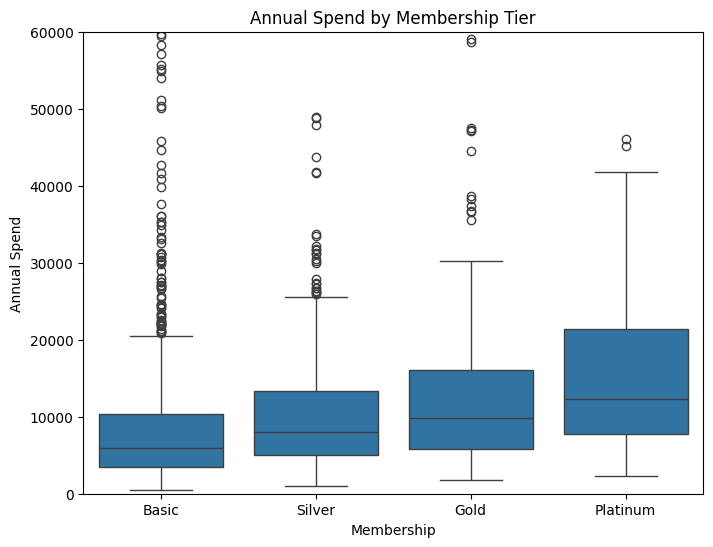

In [84]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df,x='membership',y='annual_spend',order=['Basic', 'Silver', 'Gold', 'Platinum'])
plt.title('Annual Spend by Membership Tier')
plt.ylim(0, 60000)
plt.ylabel('Annual Spend')
plt.xlabel('Membership')
plt.show()

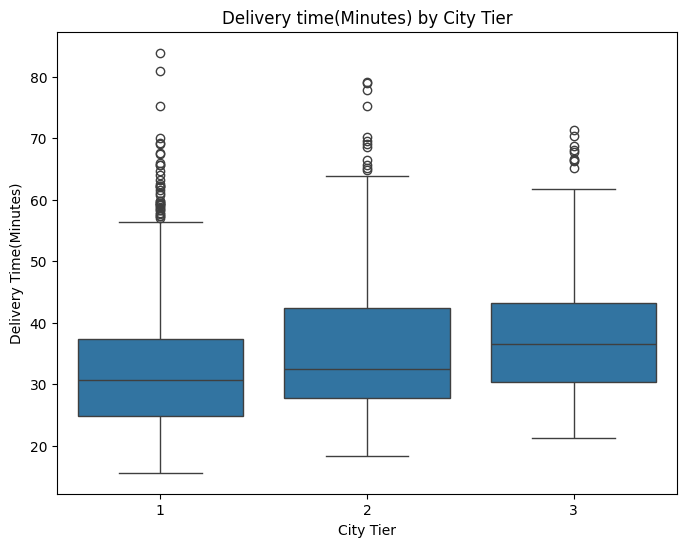

In [85]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df,x='city_tier',y='delivery_time_min')
plt.title('Delivery time(Minutes) by City Tier')
plt.ylabel('Delivery Time(Minutes)')
plt.xlabel('City Tier')
plt.show()

**Observation:**

**Task 5: Encoding Categorical Variables**

**Label/Ordinal Encoding**

In [86]:
df_enc = df.copy()

In [87]:
df_enc['membership_encoded'] = df_enc['membership'].map({'Basic':0, 'Silver':1, 'Gold':2, 'Platinum':3})

In [88]:
df_enc[['membership','membership_encoded']].head(20)

,membership,membership_encoded
0,Basic,0
1,Basic,0
2,Basic,0
3,Basic,0
4,Basic,0
5,Basic,0
6,Silver,1
7,Basic,0
8,Basic,0
9,Silver,1


**One Hot Encoding**

In [89]:
dummy = pd.get_dummies(data=df_enc[['device_type','acquisition_channel']],drop_first=True,dtype=int)

In [90]:
dummy.head()

,device_type_Web,device_type_iOS,acquisition_channel_Organic,acquisition_channel_Paid Social,acquisition_channel_Referral,acquisition_channel_Search Ads
0,0,0,0,0,1,0
1,0,1,0,0,0,0
2,0,1,0,0,1,0
3,0,0,0,1,0,0
4,0,0,0,0,0,1


In [91]:
df_enc = pd.concat([df_enc, dummy], axis=1)

In [92]:
df_enc.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,...,orders_last_12m,annual_spend,signup_month,membership_encoded,device_type_Web,device_type_iOS,acquisition_channel_Organic,acquisition_channel_Paid Social,acquisition_channel_Referral,acquisition_channel_Search Ads
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,...,17,8675.0,2023-11,0,0,0,0,0,1,0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,...,24,7896.0,2025-05,0,0,1,0,0,0,0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,...,17,1826.0,2023-02,0,0,1,0,0,1,0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,...,379,90202.0,2024-04,0,0,0,0,1,0,0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,...,17,2773.0,2025-04,0,0,0,0,0,0,1


**Target Encoding**

In [93]:
df_enc['city_encoded']= df_enc.groupby('city')['annual_spend'].transform('mean')

In [94]:
df_enc[['city', 'city_encoded']].head(10)

,city,city_encoded
0,Lucknow,13939.898649
1,Bengaluru,12004.006803
2,Indore,10732.646259
3,Jaipur,10410.643357
4,Mumbai,12020.796875
5,Kochi,15739.561905
6,Lucknow,13939.898649
7,Lucknow,13939.898649
8,Mumbai,12020.796875
9,Bengaluru,12004.006803


**Side By side Comparision of regular and encoded columns**

In [95]:
cols = ['membership', 'membership_encoded', 'city', 'city_encoded', 'device_type', 'acquisition_channel'] + list(dummy.columns)


In [96]:
df_enc[cols].head(10)

,membership,membership_encoded,city,city_encoded,device_type,acquisition_channel,device_type_Web,device_type_iOS,acquisition_channel_Organic,acquisition_channel_Paid Social,acquisition_channel_Referral,acquisition_channel_Search Ads
0,Basic,0,Lucknow,13939.898649,Android,Referral,0,0,0,0,1,0
1,Basic,0,Bengaluru,12004.006803,iOS,Influencer,0,1,0,0,0,0
2,Basic,0,Indore,10732.646259,iOS,Referral,0,1,0,0,1,0
3,Basic,0,Jaipur,10410.643357,Android,Paid Social,0,0,0,1,0,0
4,Basic,0,Mumbai,12020.796875,Android,Search Ads,0,0,0,0,0,1
5,Basic,0,Kochi,15739.561905,Android,Paid Social,0,0,0,1,0,0
6,Silver,1,Lucknow,13939.898649,iOS,Search Ads,0,1,0,0,0,1
7,Basic,0,Lucknow,13939.898649,iOS,Organic,0,1,1,0,0,0
8,Basic,0,Mumbai,12020.796875,iOS,Organic,0,1,1,0,0,0
9,Silver,1,Bengaluru,12004.006803,Android,Paid Social,0,0,0,1,0,0


**Task 5 Reflection:**



**Q - Why drop_first=True in One-Hot Encoding?**

If we Keep all **N** dummy columns then it creates Dummy Variable Trap. The **N**-th column can be 100% predicted from the remaining **N-1** columns as their sum is always 1 so, Dropping the first category serves as a baseline reference and keeps **N-1** columns.

**Q- Why Label Encoding (0–9) is Misleading for city?**

Cities have no natural rank or hierarchy(Non ordinal Data) assigning integers 0 to 9 tricks models into assuming an artificial order (e.g., City_9 > City_0) which can be misleading. To avoid that we don't use label encoding for cities.

**Q- What is the Problem with One-Hot Encoding 10 Cities?**

It creates 9-10 additional columns, increasing dataset dimensionality and in different datasets with hundreds of cities/pin codes, it can cause severe curse of dimensionality.

**Q- what is Biggest Risk of Target Encoding?**

The biggest risk of target encoding is **Data Leakage**. When we directly used the target variable (annual_spend) to create the input feature (city_encoded), the answer was leaked to the model resulting in data leakage. hence, When the new customer arrives the model will think it is working very accurately but we don't know the actual spend of the customer and it can lead to degraded generalization on unseen test data.

**Task 6: Central Tendency and Percentiles**

In [97]:
num_col = ['age', 'orders_last_12m', 'annual_spend']
summary = pd.DataFrame({'Mean': df[num_col].mean(),'Median': df[num_col].median(),
                        'Mode': df[num_col].mode().iloc[0]})
summary

,Mean,Median,Mode
age,31.9020,32.0,32.0
orders_last_12m,34.8965,24.0,17.0
annual_spend,12995.8520,7142.0,2916.0


In [98]:
df['membership'].mode().iloc[0]

'Basic'

**OBSERVATION:**

**Mean >> Median for annual spend:** The Group of vip customers with high annual spend pulls the mean towards heavy tail on right side while the annual spend of all customers (median) is relatively low. It's a strong right-skewed Pareto-like distribution.

**Business Takeaway:** If we take mean as average annual_spend of customer then it will result in overestimating the actual value effecting buisness stratergies. Median should be used to design the buisness stratergies such as pricing,discounts and marketing campaigns to attract new customers and a seperate VIP retention startergy should be discussed for heavy spenders.


**Computing percentiles (P10, P25, P50, P75, P90, P95, P99) of Delivery Time and annual spend**

In [99]:
df[['delivery_time_min','annual_spend']].quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

,delivery_time_min,annual_spend
0.10,22.100,2508.60
0.25,26.500,4085.75
0.50,32.200,7142.00
0.75,40.000,12781.25
0.90,48.910,22453.70
0.95,55.000,35355.25
0.99,67.402,109149.78


**Business question: What delivery time do 90% of customers experience or better? (P90):**

90% of customer experience waiting time of **48.9 Minutes** or better and the rest 10% of customer have to wait for more than 48.9 Minutes.

Also, we can see 99% (P99) of annual spend is: ₹1,09,149.78.
i.e. Only top 1% customers are spending more than 1,09,149.78 Rupees.

**Box Plot with Annotated Quartiles**

In [100]:
q1_dt,q2_dt,q3_dt = df['delivery_time_min'].quantile([0.25,0.5,0.75])

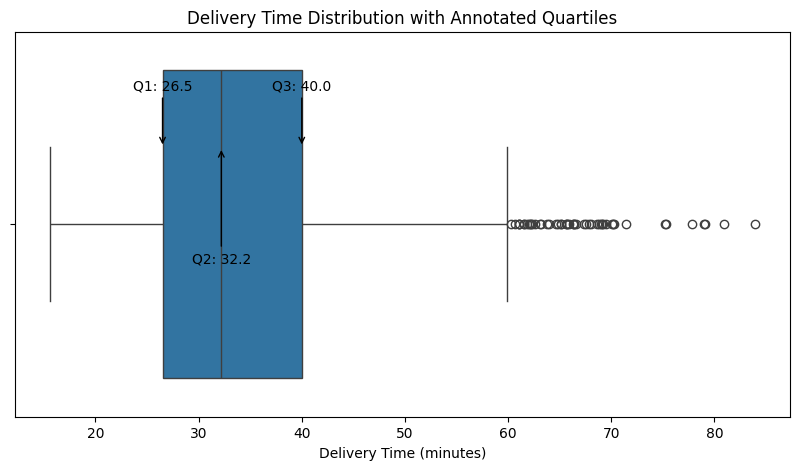

In [101]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df['delivery_time_min'])
plt.title('Delivery Time Distribution with Annotated Quartiles')
plt.xlabel('Delivery Time (minutes)')
plt.annotate(f'Q1: {q1_dt:.1f}', xy=(q1_dt, -0.2), xytext=(q1_dt, -0.35),
             ha='center', arrowprops=dict(arrowstyle='->'))
plt.annotate(f'Q2: {q2_dt:.1f}', xy=(q2_dt, -0.2), xytext=(q2_dt, 0.1),
             ha='center', arrowprops=dict(arrowstyle='->'))
plt.annotate(f'Q3: {q3_dt:.1f}', xy=(q3_dt, -0.2), xytext=(q3_dt, -0.35),
             ha='center', arrowprops=dict(arrowstyle='->'))
plt.ylim(0.5, -0.5)
plt.show()

**Task 7: Pareto Distribution and the 80/20 Rule**

**Sort customers by annual_spend , compute cumulative revenue share.**

In [102]:
pareto_df = df.sort_values(by='annual_spend', ascending=False).reset_index(drop=True)
pareto_df

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend,signup_month
0,QB100236,2025-09-09,Hyderabad,1,Female,Android,Paid Social,36.0,13.9,15,29.8,325.0,4.6,16.9,1.0,Basic,400,855443.0,2025-09
1,QB100319,2023-02-14,Nagpur,3,Unknown,Android,Paid Social,31.0,45.2,19,39.0,993.0,4.4,23.8,3.0,Platinum,400,507406.0,2023-02
2,QB100687,2023-10-27,Kochi,3,Female,Android,Referral,29.0,36.7,17,32.2,1024.0,3.3,6.1,44.0,Silver,334,364740.0,2023-10
3,QB101686,2025-02-27,Hyderabad,1,Male,Web,Search Ads,23.0,20.4,8,31.4,715.0,4.3,22.5,1.0,Basic,397,251922.0,2025-02
4,QB101830,2023-12-10,Hyderabad,1,Female,Android,Organic,28.0,35.2,16,34.0,666.0,4.2,31.9,43.0,Basic,370,207118.0,2023-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,QB101883,2023-08-20,Jaipur,2,Male,iOS,Organic,37.0,38.9,6,42.2,309.0,3.6,24.7,17.0,Basic,5,750.0,2023-08
1996,QB101360,2024-11-11,Pune,2,Male,Android,Organic,27.0,24.0,8,27.7,309.0,4.8,19.6,3.0,Basic,7,676.0,2024-11
1997,QB101794,2024-02-24,Nagpur,3,Male,iOS,Referral,41.0,32.7,13,26.5,70.0,3.8,10.6,31.0,Basic,10,662.0,2024-02
1998,QB100694,2025-01-05,Nagpur,3,Female,iOS,Organic,32.0,22.1,6,32.1,141.0,3.7,31.7,5.0,Basic,5,593.0,2025-01


In [103]:
pareto_df['cum_cust_pct'] = ((pareto_df.index + 1) / len(pareto_df)) * 100

In [104]:
pareto_df['cum_rev_pct'] = (pareto_df['annual_spend'].cumsum() / pareto_df['annual_spend'].sum()) * 100

In [105]:
pareto_df[['annual_spend', 'cum_rev_pct','cum_cust_pct']].head()

,annual_spend,cum_rev_pct,cum_cust_pct
0,855443.0,3.291216,0.05
1,507406.0,5.243400,0.10
2,364740.0,6.646694,0.15
3,251922.0,7.615934,0.20
4,207118.0,8.412796,0.25


**Plot a Pareto chart (bars for spend, line for cumulative %) or a cumulative-share curve.**

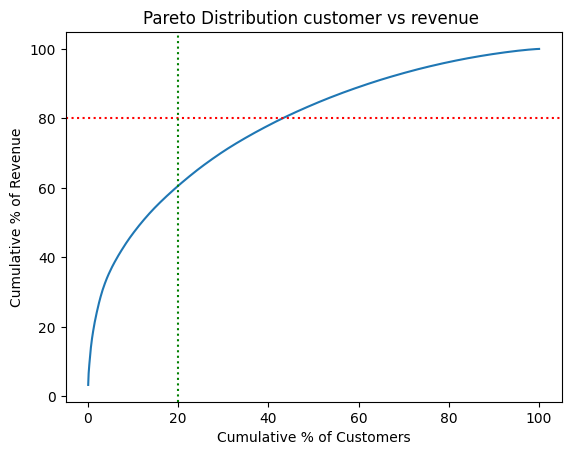

In [106]:
sns.lineplot(x=pareto_df['cum_cust_pct'],y=pareto_df['cum_rev_pct'])
plt.title('Pareto Distribution customer vs revenue ')
plt.xlabel('Cumulative % of Customers')
plt.ylabel('Cumulative % of Revenue')
plt.axhline(80, color='red', linestyle=':')
plt.axvline(20, color='green', linestyle=':')
plt.show()

**Find what percentage of customers contribute 50% and 80% of revenue and Comparing the top 20% share with the classic 80/20 idea.**

In [107]:
cust_50_rev = pareto_df[pareto_df['cum_rev_pct'] >=50 ]['cum_cust_pct'].iloc[0]
cust_80_rev = pareto_df[pareto_df['cum_rev_pct'] >=80 ]['cum_cust_pct'].iloc[0]
rev_top_20 = pareto_df[pareto_df['cum_cust_pct'] <=20 ]['cum_rev_pct'].iloc[-1]

In [108]:
print(f"Customers for 50% revenue: {cust_50_rev:.1f}%")
print(f"Customers for 80% revenue: {cust_80_rev:.1f}%")
print(f"Revenue from Top 20% customers: {rev_top_20:.1f}%")

Customers for 50% revenue: 11.9%
Customers for 80% revenue: 43.1%
Revenue from Top 20% customers: 60.6%


**Pareto Analysis & 80/20 Rule Reflection:**


50% of total revenue is generated by just the top 11.9% of customers.

80% of total revenue comes from the top 43.1% of customers.

The top 20% of customers contribute 60.6% of total revenue.

**Comparison with the Classic 80/20 Rule:**

Unlike 80/20 Pareto rule (where top 20% customers generate 80% of revenue), QuickBite's top 20% generate 60.6% meaning revenue is noticeably skewed toward high spenders.

**Business Takeaway:**

50% Revenue is generated by almost 12% of customers but the middle tier is also contributing in good numbers. so Quickbite should protect and reward the top 12%-20% high-value customers via loyalty perks or priority delivery since they drive over half the revenue, while simultaneously nudging the middle-tier customers (top 20%-45%) to increase order frequency so they move up into the high-spend segment.   

**Normal Scale vs Log Scale Plot**

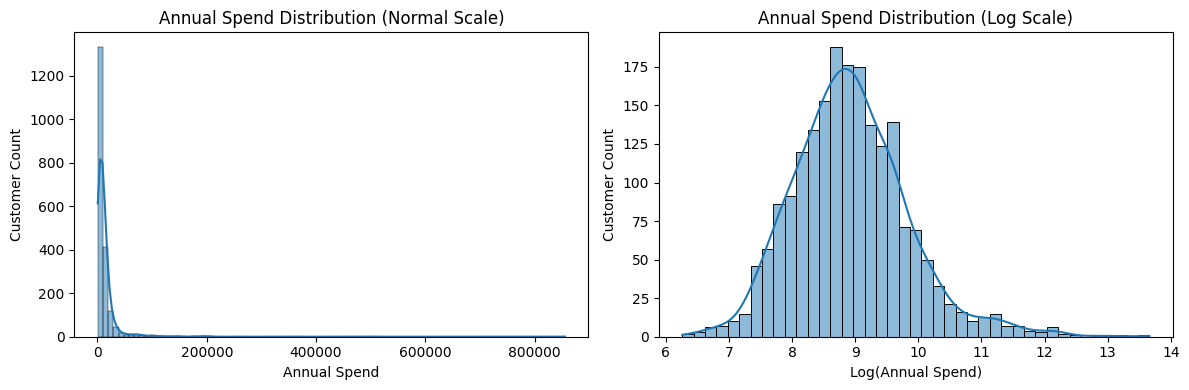

In [109]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['annual_spend'], kde=True, ax=axes[0])
axes[0].set_title('Annual Spend Distribution (Normal Scale)')
axes[0].set_xlabel('Annual Spend')
axes[0].set_ylabel('Customer Count')
sns.histplot(np.log(df['annual_spend']), kde=True, ax=axes[1])
axes[1].set_title('Annual Spend Distribution (Log Scale)')
axes[1].set_xlabel('Log(Annual Spend)')
axes[1].set_ylabel('Customer Count')
plt.tight_layout()
plt.show()

**Normal vs. Log Scale Reflection:**

Normal Scale (Left): Shows an extreme right-skewed distribution where the majority of customers are compressed near the lower spend range, while a few extreme high-spenders stretch the x-axis out past 800,000. This makes it hard to inspect variation among regular customers.

Log Scale (Right): Applying a natural log transformation compresses the extreme high values and reveals a symmetric, bell-shaped (log-normal) distribution centered around log(annual_spend). This confirms annual_spend follows a log-normal pattern and makes customer tiers much easier to visualize and model.

**Task 8: PDF and CDF**

**PDF (KDE or normalised histogram) of delivery_time_min**

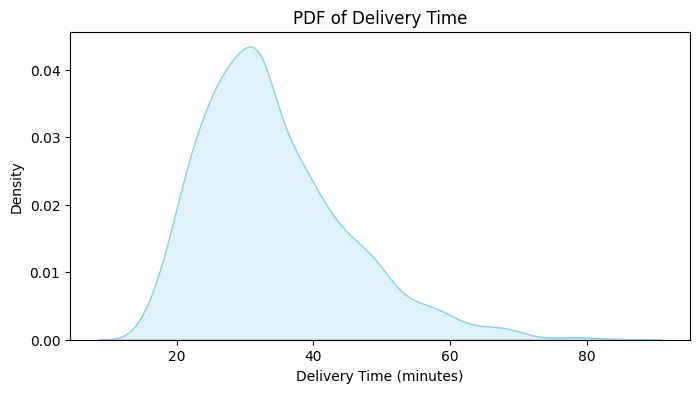

In [110]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df['delivery_time_min'],color='skyblue',fill=True)
plt.title('PDF of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Density')
plt.show()

**Empirical CDF ( np.sort + np.arange(1, n+1)/n ).**

In [111]:
x_dtm = np.sort(df['delivery_time_min'])
y_dtm = np.arange(1, len(x_dtm) + 1) / len(x_dtm)

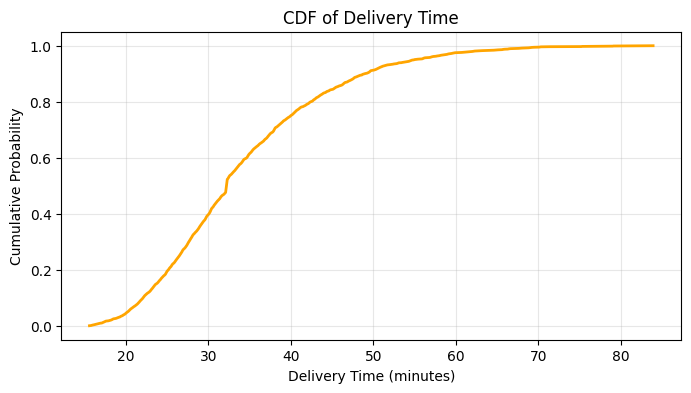

In [112]:
plt.figure(figsize=(8, 4))
sns.lineplot(x=x_dtm, y=y_dtm, color='orange', linewidth=2)
plt.title('CDF of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Cumulative Probability')
plt.grid(True, alpha=0.3)
plt.show()

**From the CDF:**

**Q- What is the probability a delivery takes ≤ 30 minutes?**

In [113]:
pb_30 = (df['delivery_time_min'] <= 30).mean()
print(f'Probability that a delivery takes ≤ 30 minutes is {pb_30*100}%')

Probability that a delivery takes ≤ 30 minutes is 39.85%


**Q- What is the probability a delivery takes > 45 minutes?**

In [114]:
pb_45 = (df['delivery_time_min']>45).mean()
print(f'probability that a delivery takes > 45 minutes is {pb_45*100}%')

probability that a delivery takes > 45 minutes is 15.6%


**Q- What time corresponds to the median and the 95th percentile?**

In [115]:
print(f'Time that corresponds to median is {(df['delivery_time_min']).median()} minutes.')
print(f'95th percentile is {df['delivery_time_min'].quantile(0.95)}')

Time that corresponds to median is 32.2 minutes.
95th percentile is 55.0


**CDF FOR AGE**

In [116]:
x_age = np.sort(df['age'])
y_age = np.arange(1, len(x_age) + 1) / len(x_age)

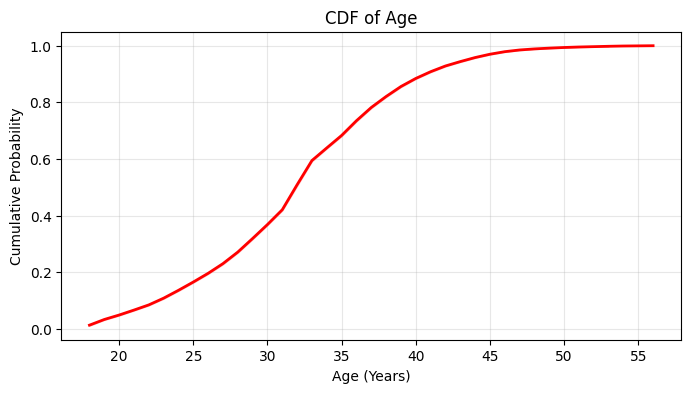

In [117]:
plt.figure(figsize=(8, 4))
sns.lineplot(x=x_age, y=y_age, color='red', linewidth=2)
plt.title('CDF of Age')
plt.xlabel('Age (Years)')
plt.ylabel('Cumulative Probability')
plt.grid(True, alpha=0.3)
plt.show()

**Comparing CDF Shapes**

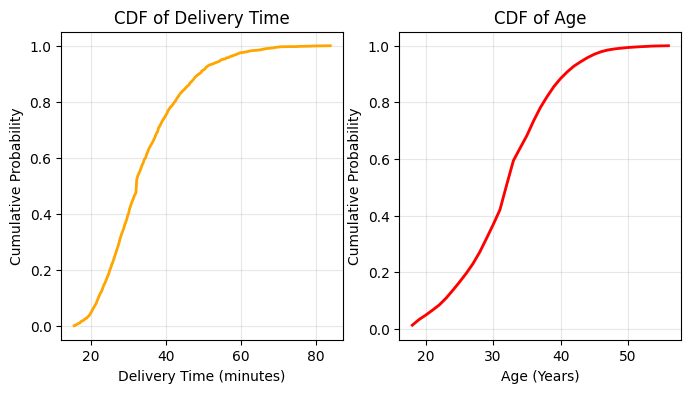

In [118]:
fig,axes = plt.subplots(1,2,figsize=(8,4))
sns.lineplot(x=x_dtm, y=y_dtm, color='orange', ax=axes[0], linewidth=2)
axes[0].set_title('CDF of Delivery Time')
axes[0].set_xlabel('Delivery Time (minutes)')
axes[0].set_ylabel('Cumulative Probability')
axes[0].grid(True, alpha=0.3)

sns.lineplot(x=x_age, y=y_age, color='red', ax=axes[1], linewidth=2)
axes[1].set_title('CDF of Age')
axes[1].set_xlabel('Age (Years)')
axes[1].set_ylabel('Cumulative Probability')
axes[1].grid(True, alpha=0.3)
plt.show()

**CDF Comparision Reflection (Delivery Time vs. Age):**

The CDF of Age is a symmetric "S" shape, which confirms that the age variable is normally distributed.

The CDF of Delivery Time rises very steeply early on and then flattens out with a long tail to the right. This reflects its right-skewed, where the majority of deliveries happen quickly, but a small percentage drag on for a much longer time.

**PDF vs CDF**

**PDF:** It shows how dense values are around a specific point. The point where the curve is at its peak is the most dense value. For example, in Delivery Time, the peak is around 30 minutes, which states that most deliveries happen around this time. It does not directly show us the percentage, rather it shows the concentration (density).

**CDF:** It shows the share or percentage of values at or below a certain point. it flows like a running total. for example around 45 minutes the CDF curve reaches 0.84, which means 84% deliveries happen in 45 min or less.